## Task 1 — Load Both Files and Reconcile Them

**Objective:** Confirm the structure and user populations of both datasets
before constructing churn labels.

**Checks:** Row counts, column data types, unique users, and the number
of users shared between the files.

**Reason:** These checks establish whether the files can be joined correctly
and identify inconsistencies before further analysis.

In [1]:
from pathlib import Path
import pandas as pd

# Locate the project folder from the root or notebooks directory.
project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Load both files, keeping user identifiers as text.
features = pd.read_csv(
    project_dir / "data/features_data.csv",
    dtype={"user_id": "string"}
)

equity = pd.read_csv(
    project_dir / "data/equity_value_data.csv",
    dtype={"user_id": "string"}
)

# Parse timestamps for reliable date arithmetic.
equity["timestamp"] = pd.to_datetime(
    equity["timestamp"], utc=True, errors="raise"
)

# Report dataset sizes and unique user counts.
summary = pd.DataFrame({
    "dataset": ["Features", "Equity"],
    "rows": [len(features), len(equity)],
    "columns": [features.shape[1], equity.shape[1]],
    "unique_users": [
        features["user_id"].nunique(),
        equity["user_id"].nunique()
    ]
})
display(summary)

# Report column types for each dataset.
for name, df in {"Features": features, "Equity": equity}.items():
    print(f"\n{name}: column data types")
    display(df.dtypes.astype(str).to_frame("data_type"))

# Reconcile the user populations.
feature_users = set(features["user_id"].dropna())
equity_users = set(equity["user_id"].dropna())

print("Users shared between files:", len(feature_users & equity_users))
print("Users only in features:", len(feature_users - equity_users))
print("Users only in equity:", len(equity_users - feature_users))

,dataset,rows,columns,unique_users
0,Features,5584,9,5584
1,Equity,1119158,3,5584



Features: column data types


,data_type
risk_tolerance,str
investment_experience,str
liquidity_needs,str
platform,str
time_spent,float64
instrument_type_first_traded,str
first_deposit_amount,float64
time_horizon,str
user_id,string



Equity: column data types


,data_type
timestamp,"datetime64[us, UTC]"
close_equity,float64
user_id,string


Users shared between files: 5584
Users only in features: 0
Users only in equity: 0


### Task 1 — Findings
The features dataset contains 5,584 rows and 9 columns, with one row per
user. The equity dataset contains 1,119,158 observations and 3 columns
for the same 5,584 users.

All user IDs match across the files. Timestamps are parsed as UTC
datetimes, allowing reliable date arithmetic. The datasets can be
linked using `user_id`.

## Task 2 — Characterise the Panel

**Objective:** Understand each user's observation coverage and determine
whether missing dates are common.

For each user, calculate the first date, last date, number of distinct
observed days, and calendar span. Subtract observed days from the calendar
span to find missing days within that range.

**Why:** We need to understand gaps before interpreting them. Total missing
days may be scattered across several periods; they do not establish churn.

**Output:** A per-user coverage table, summary statistics, and a histogram
of missing days.

,first_date,last_date,observed_days,calendar_span_days,missing_days
user_id,,,,,
0012db34aa7b083f5714e7831195e54d,2016-08-18 00:00:00+00:00,2017-08-17 00:00:00+00:00,252,365,113
001d6c77dbdb3213cead7673f250bfdc,2016-08-18 00:00:00+00:00,2017-08-17 00:00:00+00:00,252,365,113
002e4653171ddc61c3cd30603cd7bd3e,2017-02-16 00:00:00+00:00,2017-08-18 00:00:00+00:00,128,184,56
00384fa9be6fdca1b786bae70d78f88f,2017-02-23 00:00:00+00:00,2017-08-18 00:00:00+00:00,124,177,53
0042aac295a0d4df88f4b83012778bd4,2016-08-18 00:00:00+00:00,2017-08-17 00:00:00+00:00,252,365,113


,observed_days,calendar_span_days,missing_days
count,5584.00,5584.00,5584.00
mean,200.42,295.13,94.71
std,68.91,96.56,33.76
min,1.00,1.00,0.00
25%,150.00,225.00,74.75
50%,251.00,362.00,113.00
75%,252.00,365.00,113.00
max,252.00,365.00,344.00


Users with missing days: 5,560 of 5,584
Percentage: 99.6%
Median missing days: 113


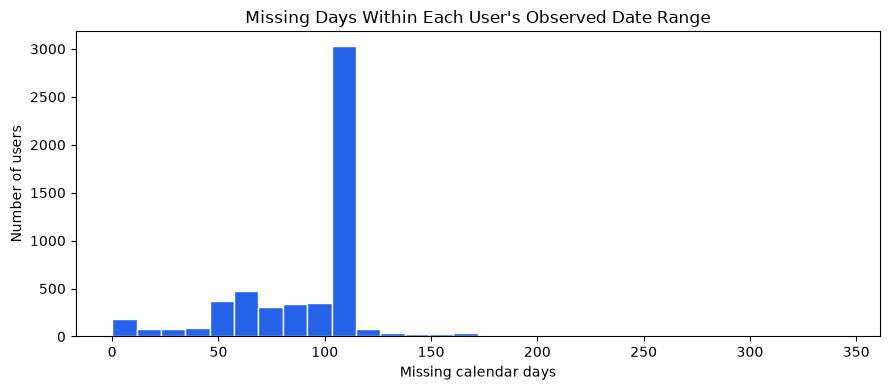

In [2]:
import matplotlib.pyplot as plt

# Summarize the recorded equity dates for each user.
panel_summary = equity.groupby("user_id").agg(
    first_date=("timestamp", "min"),
    last_date=("timestamp", "max"),
    observed_days=("timestamp", "nunique")
)

# Count calendar days, including both the first and last dates.
panel_summary["calendar_span_days"] = (
    panel_summary["last_date"] - panel_summary["first_date"]
).dt.days + 1

# Count missing days only within each user's first-to-last date range.
panel_summary["missing_days"] = (
    panel_summary["calendar_span_days"]
    - panel_summary["observed_days"]
)

# Preview the per-user coverage table.
display(panel_summary.head())

# Summarize the distribution of coverage across all users.
display(
    panel_summary[
        ["observed_days", "calendar_span_days", "missing_days"]
    ].describe().round(2)
)

# Report how common missing dates are.
users_with_gaps = panel_summary["missing_days"].gt(0).sum()
print(f"Users with missing days: {users_with_gaps:,} of {len(panel_summary):,}")
print(f"Percentage: {users_with_gaps / len(panel_summary):.1%}")
print(f"Median missing days: {panel_summary['missing_days'].median():.0f}")

# Plot the distribution of missing calendar days.
fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(
    panel_summary["missing_days"],
    bins=30,
    color="#2563EB",
    edgecolor="white"
)

ax.set(
    title="Missing Days Within Each User's Observed Date Range",
    xlabel="Missing calendar days",
    ylabel="Number of users"
)

plt.tight_layout()
plt.show()

### Task 2 — Findings

- 99.6% of users have at least one missing calendar date within their
  first-to-last observation range.
- The median user has 251 observed days across a 362-day calendar span.
- The median number of missing days is 113.
- Missing-day counts range from 0 to 344.

The histogram shows a strong concentration around 113 missing days.
Missing dates are therefore a normal feature of this panel rather than
isolated exceptions.

These counts include weekends and other unreported dates. They measure
total absence, not consecutive absence: 113 missing days does not mean
a user was absent for 113 days continuously.

**Conclusion:** Missing-day totals alone cannot identify churn. We must
establish their meaning in Task 3 and examine consecutive gaps when
implementing the churn rule.

## Task 3 — Establish What a Missing Day Means

**Objective:** Verify the equity reporting threshold and establish when
each user's churn observation begins.

**Method:** Check the minimum recorded equity and count records below
10 USD. Interpret these results using the supplied documentation, which
states that records appear only when equity is at least 10 USD.

**Reason:** Filtering existing rows for equity below 10 USD would miss
the below-threshold periods represented by absent records.

Begin counting potential churn periods only after each user's first
appearance. Earlier absence does not satisfy the requirement that the
user previously had equity of at least 10 USD.

In [3]:
# Verify that recorded equity values respect the documented threshold.
print("Minimum recorded equity:", equity["close_equity"].min())
print("Records below 10 USD:", equity["close_equity"].lt(10).sum())

# Identify when each user first meets the prior-equity requirement.
first_appearance = (
    equity.groupby("user_id")["timestamp"]
    .min()
    .rename("first_appearance")
)

print("Users with a recorded first appearance:", len(first_appearance))

Minimum recorded equity: 10.0
Records below 10 USD: 0
Users with a recorded first appearance: 5584


### Task 3 — Findings and Labeling Interpretation

The minimum recorded equity is 10 USD, and no records contain equity
below 10 USD. All 5,584 users have a recorded first appearance.

These results are consistent with the documentation stating that the
panel includes records only when equity is at least 10 USD.

Following the supplied interpretation, missing dates after a user's
first appearance will be used to identify potential below-threshold
periods. Dates before first appearance are excluded because prior
equity of at least 10 USD has not yet been established.

The panel has no weekend observations. We will explicitly document
the calendar-gap assumption when implementing the churn rule.

## Task 4 — Write the Churn Rule as a Function

**Objective:** Determine whether a user has a qualifying internal gap
of at least 28 consecutive calendar days.

**Method:** Sort and deduplicate the recorded dates, then calculate:
absent days = next recorded date − previous recorded date − 1.

For example, observations on January 1 and January 30 leave exactly
28 absent days: January 2–29.

**Reason:** Date arithmetic prevents errors caused by counting rows
or including observed endpoints.

**Scope:** Apply the calendar-gap interpretation established in Task 3.
Check internal gaps only; trailing gaps and censoring follow in Task 5.
A user who returns after a qualifying gap still has a historical churn event.

In [4]:
def has_internal_churn(dates):
    """Identify at least 28 consecutive absent calendar days between records."""

    # Convert to UTC calendar dates, remove duplicates, and sort.
    dates = pd.DatetimeIndex(
        pd.to_datetime(dates, utc=True, errors="raise")
    ).normalize().drop_duplicates().sort_values()

    # Missing timestamps cannot support a reliable label.
    if dates.isna().any():
        raise ValueError("Recorded dates must not contain missing values.")

    # Fewer than two dates cannot establish an internal gap.
    if len(dates) < 2:
        return False

    # Subtract one to exclude the observed endpoints.
    absent_days = (dates[1:] - dates[:-1]).days - 1

    # One qualifying gap is sufficient for a historical churn event.
    return bool((absent_days >= 28).any())


# Boundary check: 27 absent days do not qualify.
assert has_internal_churn(["2017-01-01", "2017-01-29"]) is False

# Boundary check: exactly 28 absent days qualify.
assert has_internal_churn(["2017-01-01", "2017-01-30"]) is True

# Unsorted and duplicate dates must not change the answer.
assert has_internal_churn(
    ["2017-01-30", "2017-01-01", "2017-01-01"]
) is True

# A record inside the gap interrupts the consecutive absence.
assert has_internal_churn(
    ["2017-01-01", "2017-01-15", "2017-01-30"]
) is False

# A single observation cannot establish an internal gap.
assert has_internal_churn(["2017-01-01"]) is False

print("Task 4: all internal-gap checks passed.")

Task 4: all internal-gap checks passed.


## Task 5 — Handle Trailing Gaps and Censoring

**Objective:** Define how to classify an absence that continues through
the end of the observation window.

**Censoring:** We cannot observe what happens after August 18, 2017.
A trailing absence shorter than 28 days has not met the churn threshold
within the available window; it may qualify later.

We will compare two labeling approaches:

1. **Internal gaps only:** Count qualifying absences between recorded dates.
2. **Internal plus trailing gaps:** Also count users whose absence has
   already reached 28 calendar days by the observation-window end.

**Primary approach:** Include qualifying trailing gaps because the required
28-day absence has already occurred within the observed window, under
the documented absence interpretation. A later return does not erase
that historical event.

The internal-only approach will be retained as a sensitivity comparison.

**Arithmetic:** Trailing absent days = observation end − last recorded date.
No subtraction is needed because the observation end is included as an
absent day when the last record precedes it.

A negative label means no qualifying event was identified under the
selected rule during the available window—not that the user will never churn.

In [5]:
def has_churn(dates, observation_end, include_trailing=True):
    """Check internal gaps and optionally a trailing gap of at least 28 days."""

    # Standardize the user's dates without changing the original data.
    dates = pd.DatetimeIndex(
        pd.to_datetime(dates, utc=True, errors="raise")
    ).normalize().drop_duplicates().sort_values()

    # Require valid observations to establish prior equity of at least 10 USD.
    if dates.isna().any() or len(dates) == 0:
        raise ValueError("Provide at least one valid recorded date.")

    # Use an explicit observation boundary for reproducibility.
    observation_end = pd.to_datetime(
        observation_end, utc=True, errors="raise"
    ).normalize()

    if pd.isna(observation_end) or dates[-1] > observation_end:
        raise ValueError("Observation end must be valid and cover all dates.")

    # A qualifying internal event remains churn even if the user returned.
    if has_internal_churn(dates):
        return True

    # Optionally count absence from the last record through the window end.
    trailing_days = (observation_end - dates[-1]).days
    return bool(include_trailing and trailing_days >= 28)


# The supplied dataset ends on August 18, 2017.
observation_end = pd.Timestamp("2017-08-18", tz="UTC")

# Exactly 28 trailing absent days qualify when trailing gaps are included.
assert has_churn(["2017-07-21"], observation_end, True) is True

# The same user has no internal gap under the internal-only approach.
assert has_churn(["2017-07-21"], observation_end, False) is False

# Only 27 trailing absent days do not qualify.
assert has_churn(["2017-07-22"], observation_end, True) is False

# An internal churn event qualifies under either approach.
assert has_churn(
    ["2017-01-01", "2017-01-30"], observation_end, False
) is True

print("Task 5: all trailing-gap and censoring checks passed.")

Task 5: all trailing-gap and censoring checks passed.


## Task 6 — Compute and Compare Churn Rates

**Objective:** Calculate the percentage of users who churned under
each of the two documented labeling approaches.

**Method:** Apply the validated function to every user's recorded dates:
1. Count qualifying internal gaps only.
2. Count qualifying internal gaps plus trailing absences of at least
   28 calendar days by August 18, 2017.

**Denominator:** All 5,584 users in the supplied dataset.

**Reason:** Comparing the results shows how the treatment of trailing
absence affects the reported churn rate.

The primary estimate includes qualifying trailing gaps. The internal-only
estimate provides a sensitivity comparison. Both follow the documented
calendar-gap interpretation and exclude dates before first appearance.

In [6]:
# Collect each user's recorded dates.
user_dates = equity.groupby("user_id")["timestamp"]

# Apply both labeling approaches, producing one row per user.
churn_labels = pd.DataFrame({
    "churn_internal_only": user_dates.apply(
        lambda dates: has_churn(
            dates, observation_end, include_trailing=False
        )
    ),
    "churn_including_trailing": user_dates.apply(
        lambda dates: has_churn(
            dates, observation_end, include_trailing=True
        )
    )
})

# Validate population coverage and consistency between the approaches.
assert set(churn_labels.index) == set(features["user_id"])
assert (
    ~churn_labels["churn_internal_only"]
    | churn_labels["churn_including_trailing"]
).all()

# Calculate counts and percentages using the same denominator.
total_users = len(churn_labels)

churn_comparison = pd.DataFrame({
    "approach": ["Internal gaps only", "Internal + trailing gaps"],
    "churned_users": [
        int(churn_labels["churn_internal_only"].sum()),
        int(churn_labels["churn_including_trailing"].sum())
    ]
})

churn_comparison["total_users"] = total_users
churn_comparison["churn_rate_pct"] = (
    100 * churn_comparison["churned_users"] / total_users
)

display(churn_comparison.round({"churn_rate_pct": 2}))

# Quantify the impact of including qualifying trailing gaps.
additional_users = int(
    (
        churn_labels["churn_including_trailing"]
        & ~churn_labels["churn_internal_only"]
    ).sum()
)

print(f"Additional users identified by trailing gaps: {additional_users:,}")
print(
    "Difference in churn rates: "
    f"{100 * additional_users / total_users:.2f} percentage points"
)

# Report each result with its assumption attached.
for row in churn_comparison.itertuples(index=False):
    print(
        f"{row.approach}: {row.churned_users:,} of "
        f"{row.total_users:,} users ({row.churn_rate_pct:.2f}%), "
        "under the documented calendar-gap interpretation."
    )

,approach,churned_users,total_users,churn_rate_pct
0,Internal gaps only,275,5584,4.92
1,Internal + trailing gaps,1005,5584,18.00


Additional users identified by trailing gaps: 730
Difference in churn rates: 13.07 percentage points
Internal gaps only: 275 of 5,584 users (4.92%), under the documented calendar-gap interpretation.
Internal + trailing gaps: 1,005 of 5,584 users (18.00%), under the documented calendar-gap interpretation.


### Task 6 — Findings: What Percentage of Users Churned?

Under the primary definition, which includes internal gaps and trailing
absences of at least 28 calendar days by August 18, 2017, **1,005 of
5,584 users churned (18.00%)**.

Counting qualifying internal gaps only identifies **275 users (4.92%)**.

Including trailing gaps identifies **730 additional users**, increasing
the estimated churn rate by **13.07 percentage points**.

**Interpretation:** The treatment of trailing absence materially affects
the result. We report 18.00% as the primary estimate and 4.92% as the
internal-only sensitivity comparison.

Both estimates use the documented calendar-gap interpretation, begin
counting after each user's first appearance, and describe historical
events within the available observation window. They do not imply that
churn is permanent or that negatively labeled users will never churn.

## Task 7 — Validate the Labels

**Objective:** Confirm that assigned labels agree with users' recorded dates.

**Method:** Inspect three users labeled churned and three labeled non-churned.
For each, display their longest internal gap and trailing absence, supported
by the actual dates.

Also inspect three edge cases:
- A user with exactly one observed day.
- A user with the most observed days.
- A user who qualifies only because of a trailing gap.

**Reason:** These checks help detect incorrect boundaries, overlooked trailing
gaps, and misleading default labels before modeling.

In [7]:
# Build an independent date-based audit table for all users.
audit_dates = (
    equity[["user_id", "timestamp"]]
    .drop_duplicates()
    .sort_values(["user_id", "timestamp"])
    .copy()
)

# Locate the recorded dates bounding each internal absence.
audit_dates["previous_date"] = (
    audit_dates.groupby("user_id")["timestamp"].shift()
)
audit_dates["absent_days"] = (
    audit_dates["timestamp"] - audit_dates["previous_date"]
).dt.days - 1

# Summarize the evidence supporting each user's labels.
label_audit = audit_dates.groupby("user_id").agg(
    first_date=("timestamp", "min"),
    last_date=("timestamp", "max"),
    observed_days=("timestamp", "nunique"),
    longest_internal_gap=("absent_days", "max")
)

# A single observation has no internal gap.
label_audit["longest_internal_gap"] = (
    label_audit["longest_internal_gap"].fillna(0).astype(int)
)
label_audit["trailing_days"] = (
    observation_end - label_audit["last_date"]
).dt.days

label_audit = label_audit.join(churn_labels, validate="one_to_one")

# Independently verify every label using the gap summaries.
assert (
    label_audit["churn_internal_only"]
    == label_audit["longest_internal_gap"].ge(28)
).all()

assert (
    label_audit["churn_including_trailing"]
    == (
        label_audit["longest_internal_gap"].ge(28)
        | label_audit["trailing_days"].ge(28)
    )
).all()


def inspect_user(user_id, description):
    """Display one user's label and the dates supporting it."""

    print(f"\n{description}")
    display(label_audit.loc[[user_id]])

    # Show the three longest internal gaps with their observed endpoints.
    user_records = audit_dates.loc[audit_dates["user_id"].eq(user_id)]
    display(
        user_records.dropna(subset=["previous_date"])
        .nlargest(3, "absent_days")[
            ["previous_date", "timestamp", "absent_days"]
        ]
        .rename(columns={"timestamp": "next_recorded_date"})
    )

    # Show the endpoints used to calculate the trailing absence.
    print(
        f"Last record: {label_audit.loc[user_id, 'last_date'].date()} | "
        f"Window end: {observation_end.date()} | "
        f"Trailing absence: {label_audit.loc[user_id, 'trailing_days']} days"
    )


# Inspect three users from each primary-label group reproducibly.
for label, description in [(True, "Churned"), (False, "Non-churned")]:
    selected = label_audit.loc[
        label_audit["churn_including_trailing"].eq(label)
    ].sample(n=3, random_state=42)

    for number, user_id in enumerate(selected.index, start=1):
        inspect_user(user_id, f"{description} example {number}")

# Deliberately inspect the edge cases required by the assignment.
single_day_users = label_audit.loc[label_audit["observed_days"].eq(1)]
if not single_day_users.empty:
    inspect_user(single_day_users.index[0], "Edge case: one observed day")

inspect_user(
    label_audit["observed_days"].idxmax(),
    "Edge case: maximum observed days"
)

trailing_only_users = label_audit.loc[
    ~label_audit["churn_internal_only"]
    & label_audit["churn_including_trailing"]
]
if not trailing_only_users.empty:
    inspect_user(
        trailing_only_users.index[0],
        "Edge case: churn identified only by trailing absence"
    )

print("\nAll labels agree with the independent gap calculations.")


Churned example 1


,first_date,last_date,observed_days,longest_internal_gap,trailing_days,churn_internal_only,churn_including_trailing
user_id,,,,,,,
eb0a55af70b92d4af9f3dc460b6fb0b9,2017-02-10 00:00:00+00:00,2017-08-18 00:00:00+00:00,81,75,0,True,True


,previous_date,next_recorded_date,absent_days
790917,2017-04-12 00:00:00+00:00,2017-06-27 00:00:00+00:00,75.0
790880,2017-02-17 00:00:00+00:00,2017-02-21 00:00:00+00:00,3.0
790875,2017-02-10 00:00:00+00:00,2017-02-13 00:00:00+00:00,2.0


Last record: 2017-08-18 | Window end: 2017-08-18 | Trailing absence: 0 days

Churned example 2


,first_date,last_date,observed_days,longest_internal_gap,trailing_days,churn_internal_only,churn_including_trailing
user_id,,,,,,,
9eb990bc54dea1a88189937411c3b279,2017-02-02 00:00:00+00:00,2017-02-21 00:00:00+00:00,13,3,178,False,True


,previous_date,next_recorded_date,absent_days
1020035,2017-02-17 00:00:00+00:00,2017-02-21 00:00:00+00:00,3.0
1020025,2017-02-03 00:00:00+00:00,2017-02-06 00:00:00+00:00,2.0
1020030,2017-02-10 00:00:00+00:00,2017-02-13 00:00:00+00:00,2.0


... (18 outputs left out)

Last record: 2017-08-17 | Window end: 2017-08-18 | Trailing absence: 1 days

Edge case: churn identified only by trailing absence


,first_date,last_date,observed_days,longest_internal_gap,trailing_days,churn_internal_only,churn_including_trailing
user_id,,,,,,,
004aab1640f3a04b87b1f404fb4c018d,2017-01-13 00:00:00+00:00,2017-04-28 00:00:00+00:00,66,11,112,False,True


,previous_date,next_recorded_date,absent_days
959260,2017-01-19 00:00:00+00:00,2017-01-31 00:00:00+00:00,11.0
959257,2017-01-13 00:00:00+00:00,2017-01-17 00:00:00+00:00,3.0
959274,2017-02-17 00:00:00+00:00,2017-02-21 00:00:00+00:00,3.0


Last record: 2017-04-28 | Window end: 2017-08-18 | Trailing absence: 112 days

All labels agree with the independent gap calculations.


### Task 7 — Validation Findings

All user labels agree with independently calculated internal and trailing
gap lengths.

Manual inspection covered three churned users, three non-churned users,
and the required edge cases.

- A 75-day internal absence correctly identifies a historical churn event,
  even though the user subsequently returned.
- Trailing absences of 178 and 42 days correctly qualify under the
  primary approach.
- The three non-churned examples have no internal or trailing absence
  reaching 28 days.
- A user with one observation has no internal gap but qualifies through
  a 190-day trailing absence.
- The user with the maximum observed days has no qualifying gap.
- The trailing-only example demonstrates why the two labeling approaches
  produce different results.

**Conclusion:** The labels are consistent with the implemented calendar-gap
rules. This validates the implementation; it does not independently verify
unobserved balances or eliminate the reporting-calendar assumptions.

## Task 8 — Build the Feature Table

**Objective:** Create one row per user containing the supplied predictors
and the validated churn label.

**Method:** Join features to labels using `user_id`, enforcing a one-to-one
match. Use the primary label, which includes qualifying trailing gaps.

**Target:** `churn = 1` indicates a qualifying historical churn event;
`churn = 0` indicates no event identified within the observation window.

**Feature preparation:**
- Treat the six text predictors as categorical.
- Treat `time_spent` and `first_deposit_amount` as numeric.
- Use `user_id` only for matching.
- Check missing values explicitly; do not silently drop users.

Encoding, imputation if needed, and scaling will be fitted within training
pipelines after splitting in Task 9.

**Leakage control:** Use only predictors from `features_data.csv`.
Exclude equity-derived dates, gap lengths, and alternative churn labels.

**Limitation:** Feature measurement timestamps are unavailable. In particular,
the timing of `time_spent` must be acknowledged when interpreting predictive
results; prospective performance is not established by this dataset alone.

In [8]:
# Define predictor types explicitly.
categorical_features = [
    "risk_tolerance",
    "investment_experience",
    "liquidity_needs",
    "platform",
    "instrument_type_first_traded",
    "time_horizon"
]

numeric_features = [
    "time_spent",
    "first_deposit_amount"
]

predictor_columns = categorical_features + numeric_features

# Select only the primary label and encode it as 0 or 1.
primary_labels = (
    churn_labels[["churn_including_trailing"]]
    .rename(columns={"churn_including_trailing": "churn"})
    .reset_index()
)
primary_labels["churn"] = primary_labels["churn"].astype(int)

# Require valid matching keys before merging.
assert features["user_id"].notna().all()
assert primary_labels["user_id"].notna().all()

# Join by user ID and verify that each user matches exactly once.
model_data = features[["user_id"] + predictor_columns].merge(
    primary_labels,
    on="user_id",
    how="outer",
    validate="one_to_one",
    indicator=True
)

assert model_data["_merge"].eq("both").all(), "Unmatched users detected."
model_data = model_data.drop(columns="_merge")

# Confirm population size and valid target values.
assert len(model_data) == len(features) == len(churn_labels)
assert model_data["churn"].isin([0, 1]).all()

# Inspect missing values before deciding whether imputation is necessary.
display(model_data.isna().sum().to_frame("missing_values"))

# Separate predictors and target; retain IDs only as the row index.
indexed_data = model_data.set_index("user_id")
X = indexed_data[predictor_columns].copy()
y = indexed_data["churn"].copy()

print("Model table — rows, columns:", model_data.shape)
print("Predictor table — rows, columns:", X.shape)

# Summarize class balance.
class_summary = (
    y.value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("churn")
    .to_frame("users")
)
class_summary["percentage"] = (
    100 * class_summary["users"] / len(y)
).round(2)

display(class_summary)

,missing_values
user_id,0
risk_tolerance,0
investment_experience,0
liquidity_needs,0
platform,0
instrument_type_first_traded,0
time_horizon,0
time_spent,0
first_deposit_amount,0
churn,0


Model table — rows, columns: (5584, 10)
Predictor table — rows, columns: (5584, 8)


,users,percentage
churn,,
0,4579,82.0
1,1005,18.0


### Task 8 — Findings

The feature table contains 5,584 users, with eight predictors and one
validated churn label per user. All users matched successfully, and
no missing values were detected; no imputation is currently required.

The target distribution is:
- **Churn = 0:** 4,579 users (82.00%).
- **Churn = 1:** 1,005 users (18.00%).

The classes are imbalanced. Predicting no churn for everyone would achieve
82% accuracy while identifying zero churners. Model evaluation must therefore
consider precision, recall, and the precision–recall curve alongside accuracy.

The user identifier is excluded from predictors. Encoding and any required
scaling will be fitted using training data only.

Class weighting and SMOTENC may be evaluated during model development;
the 18% churn prevalence alone does not establish that resampling is needed.

## Task 9 — Split, Baseline, and Model

### 9.1 — Create Training and Test Sets

**Objective:** Reserve unseen users for final model evaluation.

**Method:** Allocate 80% of users to training and 20% to testing,
stratified by churn label to preserve approximately the same class balance.

**Reason:** Encoding, scaling, resampling, hyperparameter tuning, and
threshold selection must use training data only. Cross-validation within
the training set will support these decisions.

The test set will remain reserved until the model and threshold are fixed.

**Scope:** This split evaluates generalization to held-out users from the
supplied population. It does not establish performance on future cohorts.

In [9]:
# Install scikit-learn in the active notebook environment.
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [10]:
from sklearn.model_selection import train_test_split

# Reserve 20% of users for final evaluation.
# Stratification preserves the approximate churn proportion.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Confirm that users do not appear in both sets.
assert X_train.index.intersection(X_test.index).empty

# Confirm predictors and targets remain aligned.
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

# Summarize split sizes and class balance.
split_summary = pd.DataFrame({
    "dataset": ["Training", "Test"],
    "users": [len(y_train), len(y_test)],
    "churned_users": [int(y_train.sum()), int(y_test.sum())],
    "churn_rate_pct": [
        100 * y_train.mean(),
        100 * y_test.mean()
    ]
})

display(split_summary.round({"churn_rate_pct": 2}))

,dataset,users,churned_users,churn_rate_pct
0,Training,4467,804,18.00
1,Test,1117,201,17.99


### Task 9.2 — Establish the Majority-Class Baseline

**Objective:** Establish a reference against which to compare our models.

**Method:** Use a classifier that always predicts the most common training
label: no churn. Evaluate it with five-fold stratified cross-validation
within the training set.

**Reason:** A model can achieve approximately 82% accuracy without
identifying any churners. The baseline makes this limitation explicit.

The final test set remains reserved for evaluation after model development.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score

# Use reproducible folds that preserve the approximate class balance.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Always predict the most frequent label in each training fold.
baseline = DummyClassifier(strategy="most_frequent")

# Precision is set to zero when no users are predicted to churn.
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0)
}

# Evaluate using training data only.
baseline_cv = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Report mean performance across the validation folds.
baseline_results = pd.DataFrame({
    "model": ["Majority-class baseline"],
    "cv_accuracy": [baseline_cv["test_accuracy"].mean()],
    "cv_precision": [baseline_cv["test_precision"].mean()],
    "cv_recall": [baseline_cv["test_recall"].mean()]
})

display(baseline_results.round(4))

,model,cv_accuracy,cv_precision,cv_recall
0,Majority-class baseline,0.82,0.0,0.0


### Task 9.3 — Build the Logistic Regression Pipeline

**Objective:** Build an interpretable model that estimates churn probabilities.

**Preprocessing:**
- One-hot encode categorical predictors without imposing an artificial order.
- Standardize numeric predictors so their scales do not disproportionately
  affect regularization.
- Fit all preprocessing inside each training fold to prevent leakage.

**Model:** Start with logistic regression using the original class distribution.
Class weighting, hyperparameter tuning, and resampling will be assessed later.

**Evaluation:** Use the same five stratified folds as the baseline. Report
accuracy, precision, recall, average precision, and ROC-AUC.
Average precision summarizes precision–recall performance; its no-skill
reference is approximately the 18% churn prevalence.

Precision and recall initially use the default 0.50 threshold.
Threshold selection follows in Task 10.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Encode categories and scale numeric values within the pipeline.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

# Combine preprocessing and logistic regression into one pipeline.
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

# Extend the baseline metrics with probability-ranking measures.
model_scoring = {
    **scoring,
    "average_precision": "average_precision",
    "roc_auc": "roc_auc"
}

# Fit and evaluate independently within each training fold.
logistic_cv = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=model_scoring,
    return_train_score=True,
    error_score="raise"
)

# Compare training and validation performance to assess overfitting.
logistic_results = pd.DataFrame([
    {
        "metric": metric,
        "training_mean": logistic_cv[f"train_{metric}"].mean(),
        "validation_mean": logistic_cv[f"test_{metric}"].mean(),
        "validation_std": logistic_cv[f"test_{metric}"].std(ddof=1)
    }
    for metric in model_scoring
])

display(logistic_results.round(4))

,metric,training_mean,validation_mean,validation_std
0,accuracy,0.8200,0.8193,0.0010
1,precision,0.5000,0.0667,0.1491
2,recall,0.0025,0.0012,0.0028
3,average_precision,0.2972,0.2730,0.0166
4,roc_auc,0.6534,0.6328,0.0218


### Task 9.3 — Logistic Regression Findings

Logistic regression achieved validation average precision of 0.2730
and ROC-AUC of 0.6328, indicating modest predictive signal.

At the default 0.50 threshold, recall was only 0.12%. The model therefore
identifies almost no churners at this operating point. Its 81.93% accuracy
does not improve on the approximately 82% majority-class baseline.

Precision varies substantially across folds because very few positive
predictions are made. The mean precision should therefore be interpreted
cautiously.

Training average precision was 0.2972 versus 0.2730 in validation.
This difference suggests some optimism in training performance, without
a large observed training–validation gap.

**Decision:** Retain logistic regression as an interpretable reference.
Compare it with a tree ensemble, then assess tuning, class weighting,
and threshold selection using training data only.

In [13]:
from sklearn.ensemble import RandomForestClassifier

# Trees do not require numeric scaling.
# Categories still need encoding, fitted separately within each fold.
forest_preprocessor = ColumnTransformer([
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    ("numeric", "passthrough", numeric_features)
])

# Start with a constrained forest to limit overly complex trees.
# These are initial settings; tuning follows after this comparison.
forest_pipeline = Pipeline([
    ("preprocessor", forest_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Use the same folds and metrics for a comparable evaluation.
forest_cv = cross_validate(
    forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=model_scoring,
    return_train_score=True,
    error_score="raise"
)

# Examine training performance, validation performance, and fold variation.
forest_results = pd.DataFrame([
    {
        "metric": metric,
        "training_mean": forest_cv[f"train_{metric}"].mean(),
        "validation_mean": forest_cv[f"test_{metric}"].mean(),
        "validation_std": forest_cv[f"test_{metric}"].std(ddof=1)
    }
    for metric in model_scoring
])

display(forest_results.round(4))

,metric,training_mean,validation_mean,validation_std
0,accuracy,0.8200,0.8200,0.0005
1,precision,0.0000,0.0000,0.0000
2,recall,0.0000,0.0000,0.0000
3,average_precision,0.4329,0.3075,0.0164
4,roc_auc,0.7628,0.6650,0.0135


### Task 9.4 — Random Forest Findings

The initial Random Forest achieved validation average precision of 0.3075
and ROC-AUC of 0.6650, exceeding the initial logistic regression results
on both ranking measures.

At the default 0.50 threshold, the forest predicted no churners.
Its 82% accuracy therefore matches the majority-class baseline, with
zero precision and recall.

Training average precision was 0.4329 compared with 0.3075 in validation,
indicating overfitting. Fold-to-fold validation variation was relatively
small, but this does not remove the training–validation gap.

**Decision:** Tune model complexity and compare class weighting using
training cross-validation. Select models primarily by average precision.
Choose an operating threshold separately in Task 10, using development
predictions and a stated retention objective.

### Task 9.5 — Tune Logistic Regression

**Objective:** Assess whether regularization and class weighting improve
validation performance.

**Method:** Compare five regularization strengths with and without balanced
class weights using the existing five-fold training cross-validation.

Smaller C values impose stronger regularization. Balanced class weights
increase the penalty for misclassifying churners.

**Selection metric:** Average precision, because churners are a minority
and the model should rank them above non-churners.

The best cross-validation score is a development estimate, not a final
performance claim. The test set remains untouched.

In [14]:
from sklearn.model_selection import GridSearchCV

# Compare regularization strength and class weighting.
logistic_param_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
    "model__class_weight": [None, "balanced"]
}

# Preprocessing is fitted inside each fold through the existing pipeline.
logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    scoring=model_scoring,
    refit="average_precision",
    cv=cv,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise"
)

logistic_search.fit(X_train, y_train)

# Retain the selected pipeline, fitted on the full training set.
best_logistic = logistic_search.best_estimator_

# Display all configurations to assess weighting and regularization.
logistic_tuning_results = pd.DataFrame(logistic_search.cv_results_)

display(
    logistic_tuning_results[[
        "param_model__C",
        "param_model__class_weight",
        "mean_train_average_precision",
        "mean_test_average_precision",
        "std_test_average_precision",
        "mean_test_roc_auc",
        "mean_test_precision",
        "mean_test_recall"
    ]]
    .sort_values("mean_test_average_precision", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

print("Selected parameters:", logistic_search.best_params_)

,param_model__C,param_model__class_weight,mean_train_average_precision,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc,mean_test_precision,mean_test_recall
0,0.10,NaN,0.2963,0.2811,0.0131,0.6352,0.0000,0.0000
1,0.01,NaN,0.2853,0.2789,0.0102,0.6330,0.0000,0.0000
2,0.01,balanced,0.2876,0.2783,0.0108,0.6333,0.2401,0.5722
3,0.10,balanced,0.2938,0.2776,0.0130,0.6325,0.2429,0.5747
4,1.00,NaN,0.2972,0.2730,0.0149,0.6328,0.0667,0.0012
5,10.00,NaN,0.2977,0.2710,0.0169,0.6318,0.1167,0.0025
6,100.00,NaN,0.2977,0.2710,0.0169,0.6315,0.1067,0.0025
7,1.00,balanced,0.2939,0.2710,0.0158,0.6294,0.2447,0.5772
8,10.00,balanced,0.2943,0.2707,0.0181,0.6290,0.2445,0.5747
9,100.00,balanced,0.2946,0.2698,0.0175,0.6286,0.2443,0.5747


Selected parameters: {'model__C': 0.1, 'model__class_weight': None}


### Task 9.5 — Logistic Regression Tuning: Findings

We compared five regularization strengths with and without balanced class
weights using five-fold stratified cross-validation on the training data.

The selected configuration was C = 0.1 with no class weighting. Mean
validation average precision increased from 0.2730 to 0.2811. Training
average precision was 0.2963.

The improvement is modest and does not establish a statistically significant
difference. Balanced class weights did not improve average precision in
this search. The test set remains reserved for final evaluation.

### Task 9.6 — Tune the Random Forest

Compare tree depth, minimum leaf size, and class weighting using five-fold
stratified cross-validation on the training data.

Select the configuration with the highest mean validation average precision.
These settings control model complexity and assess whether class weighting
helps rank churners. Keep the test set untouched.

In [15]:
from sklearn.base import clone

# Let GridSearchCV parallelize the search while each forest runs serially.
forest_for_search = clone(forest_pipeline)
forest_for_search.set_params(model__n_jobs=1)

forest_param_grid = {
    "model__max_depth": [5, 8, None],
    "model__min_samples_leaf": [5, 10, 20],
    "model__class_weight": [None, "balanced"],
}

forest_search = GridSearchCV(
    estimator=forest_for_search,
    param_grid=forest_param_grid,
    scoring=model_scoring,
    refit="average_precision",
    cv=cv,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
)

# Fit preprocessing and models within each training fold.
forest_search.fit(X_train, y_train)

best_forest = forest_search.best_estimator_
forest_tuning_results = pd.DataFrame(forest_search.cv_results_)

# Show the five strongest configurations without a wide, scrolling table.
forest_top_results = (
    forest_tuning_results[
        [
            "param_model__max_depth",
            "param_model__min_samples_leaf",
            "param_model__class_weight",
            "mean_train_average_precision",
            "mean_test_average_precision",
            "std_test_average_precision",
        ]
    ]
    .rename(columns={
        "param_model__max_depth": "depth",
        "param_model__min_samples_leaf": "min_leaf",
        "param_model__class_weight": "class_weight",
        "mean_train_average_precision": "train_AP",
        "mean_test_average_precision": "validation_AP",
        "std_test_average_precision": "validation_AP_std",
    })
    .sort_values("validation_AP", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

display(forest_top_results.round(4))
print("Selected parameters:", forest_search.best_params_)

,depth,min_leaf,class_weight,train_AP,validation_AP,validation_AP_std
0,5,20,NaN,0.3639,0.3130,0.0161
1,5,10,NaN,0.3772,0.3118,0.0184
2,5,5,NaN,0.3902,0.3110,0.0173
3,5,10,balanced,0.3695,0.3106,0.0171
4,8,20,balanced,0.3886,0.3103,0.0184


Selected parameters: {'model__class_weight': None, 'model__max_depth': 5, 'model__min_samples_leaf': 20}


### Task 9.6 — Random Forest Tuning: Findings

The selected random forest used a maximum depth of 5, a minimum of 20
samples per leaf, and no class weighting. Mean validation average precision
was 0.3130, up from 0.3075 for the initial forest. The gap between training
and validation average precision narrowed from 0.1254 to 0.0509.

The tuned forest had the highest mean validation average precision among
the models evaluated and was selected for threshold development. We
deferred SMOTE and will first assess whether adjusting the decision
threshold gives a useful precision–recall trade-off for retention outreach.

### Task 10.1 — Generate Out-of-Fold Churn Scores

Use five-fold stratified cross-validation to generate one churn score for
each training user. Each score comes from a random forest fitted on the
other four folds. These scores provide the basis for comparing outreach
thresholds in Task 10.2.

The model scored all 4,467 training users. The highest score was 0.3733,
so the default cutoff of 0.50 flagged zero users.

Because the same folds were used to select the random forest settings,
these scores are for threshold development. The held-out test set will
be used for final evaluation after the threshold is selected.

In [16]:
from sklearn.model_selection import cross_val_predict

# Generate out-of-fold scores for the churn class (class 1).
forest_oof_scores = cross_val_predict(
    best_forest,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

# Pair each score with the user's observed churn label.
threshold_data = pd.DataFrame(
    {
        "churn": y_train,
        "churn_score": forest_oof_scores,
    },
    index=y_train.index,
)

# Summarize the scores and check the default cutoff.
display(threshold_data["churn_score"].describe().round(4))
print(f"Users scored: {len(threshold_data):,}")
print(f"Users flagged at 0.50: {(forest_oof_scores >= 0.50).sum():,}")

count    4467.0000
mean        0.1795
std         0.0598
min         0.0670
25%         0.1356
50%         0.1697
75%         0.2146
max         0.3733
Name: churn_score, dtype: float64

Users scored: 4,467
Users flagged at 0.50: 0


### Task 10.2 — Examine the Precision–Recall Trade-off

Plot precision and recall using the random forest's out-of-fold training
scores. Precision measures the share of flagged users who churned.
Recall measures the share of churners the model flagged.

Use the training churn rate of approximately 18% as the reference for
random outreach. For a low-cost in-app reminder, we prioritize reaching
more churners while tracking the share of users flagged. The curve will
help us identify candidate cutoffs for comparison before final evaluation
on the held-out test set.

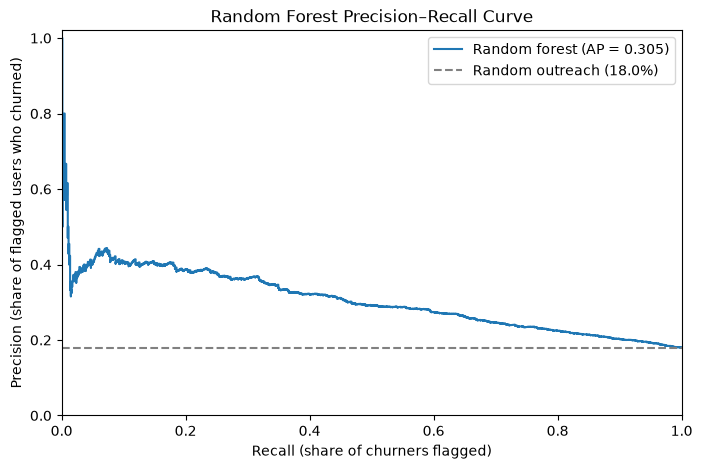

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve

# Use the observed labels and out-of-fold scores from Task 10.1.
labels = threshold_data["churn"]
scores = threshold_data["churn_score"]

precision, recall, _ = precision_recall_curve(labels, scores)
oof_ap = average_precision_score(labels, scores)
churn_rate = labels.mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.step(
    recall[::-1],
    precision[::-1],
    where="pre",
    label=f"Random forest (AP = {oof_ap:.3f})",
)
ax.axhline(
    churn_rate,
    color="gray",
    linestyle="--",
    label=f"Random outreach ({churn_rate:.1%})",
)
ax.set(
    title="Random Forest Precision–Recall Curve",
    xlabel="Recall (share of churners flagged)",
    ylabel="Precision (share of flagged users who churned)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend()
plt.show()

### Task 10.2 — Precision–Recall Findings

The random forest achieved a pooled out-of-fold average precision of
0.305, compared with a random outreach reference of 0.180.

At approximately 60% recall, precision was about 28%. This operating
point would capture roughly six in ten churners, with about 28 churners
per 100 users flagged. These values are approximate readings from the
development curve.

### Task 10.3 — Compare Candidate Thresholds

Compare candidate cutoffs using the random forest's out-of-fold scores.
For each cutoff, report precision, recall, F2, and the number and share
of users flagged. For the assumed low-cost in-app reminder, use F2 to
favor recall and review how many users each cutoff would flag.

In [18]:
from sklearn.metrics import fbeta_score, precision_score, recall_score

labels = threshold_data["churn"]
scores = threshold_data["churn_score"]
candidate_cutoffs = [0.15, 0.175, 0.20, 0.225, 0.25, 0.275, 0.30]

rows = []
for cutoff in candidate_cutoffs:
    # Flag users whose score meets or exceeds the cutoff.
    flagged = scores >= cutoff
    rows.append({
        "cutoff": cutoff,
        "precision": precision_score(labels, flagged, zero_division=0),
        "recall": recall_score(labels, flagged, zero_division=0),
        "F2": fbeta_score(labels, flagged, beta=2, zero_division=0),
        "users_flagged": int(flagged.sum()),
        "pct_flagged": 100 * flagged.mean(),
    })

threshold_comparison = pd.DataFrame(rows)
display(threshold_comparison.round(3))

,cutoff,precision,recall,F2,users_flagged,pct_flagged
0,0.150,0.224,0.801,0.529,2869,64.227
1,0.175,0.257,0.665,0.505,2082,46.608
2,0.200,0.288,0.519,0.447,1449,32.438
3,0.225,0.326,0.372,0.362,916,20.506
4,0.250,0.368,0.256,0.273,560,12.536
5,0.275,0.395,0.183,0.205,372,8.328
6,0.300,0.408,0.116,0.135,228,5.104


### Task 10.3 — Select the Outreach Threshold

We selected a churn score cutoff of 0.175 using the random forest's
out-of-fold training scores. At this cutoff, the model flagged 2,082 of
4,467 users (46.6%), with 25.7% precision, 66.5% recall, and an F2 score
of 0.505.

The 0.150 cutoff had the highest F2 among the cutoffs tested (0.529),
but it flagged 64.2% of users. For the assumed low-cost in-app reminder,
we chose 0.175 to reach about two-thirds of observed churners while
flagging fewer than half of the development users. This is a scenario
assumption rather than a confirmed campaign capacity limit.

### Task 10.4 — Evaluate on the Held-Out Test Set

Score the held-out users with the fitted random forest and apply the
0.175 cutoff selected from out-of-fold training scores. Report precision,
recall, F2, and outreach volume at this cutoff. Use a confusion matrix
to show the counts behind these metrics.

Report average precision to evaluate the ranking across cutoffs, and
compare the results with a baseline that always predicts no churn.

In [19]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    fbeta_score,
    precision_score,
    recall_score,
)

# Apply the cutoff selected before looking at the test results.
selected_threshold = 0.175
test_scores = best_forest.predict_proba(X_test)[:, 1]
test_flagged = test_scores >= selected_threshold

# The majority-class baseline assigns the same score to every user.
baseline_scores = np.full(len(y_test), y_train.mean())
baseline_flagged = np.zeros(len(y_test), dtype=bool)

rows = []
for model, scores, flagged in [
    ("Majority-class baseline", baseline_scores, baseline_flagged),
    ("Random forest at 0.175", test_scores, test_flagged),
]:
    rows.append({
        "model": model,
        "accuracy": accuracy_score(y_test, flagged),
        "precision": precision_score(y_test, flagged, zero_division=0),
        "recall": recall_score(y_test, flagged, zero_division=0),
        "F2": fbeta_score(y_test, flagged, beta=2, zero_division=0),
        "average_precision": average_precision_score(y_test, scores),
        "users_flagged": int(flagged.sum()),
        "pct_flagged": 100 * flagged.mean(),
    })

display(pd.DataFrame(rows).set_index("model").round(3))

# Rows show observed outcomes. Columns show the outreach decision.
test_confusion = pd.DataFrame(
    confusion_matrix(y_test, test_flagged, labels=[0, 1]),
    index=["Did not churn", "Churned"],
    columns=["Unflagged", "Flagged"],
)
display(test_confusion)

,accuracy,precision,recall,F2,average_precision,users_flagged,pct_flagged
model,,,,,,,
Majority-class baseline,0.820,0.000,0.000,0.00,0.180,0,0.000
Random forest at 0.175,0.593,0.261,0.692,0.52,0.315,532,47.628


,Unflagged,Flagged
Did not churn,523,393
Churned,62,139


### Task 10.4 — Held-Out Test Findings

We evaluated the random forest on 1,117 held-out users using the 0.175
cutoff selected during development. The model flagged 139 of 201 churners
and missed 62. It also flagged 393 non-churners. In total, it flagged
532 users (47.6%), with 26.1% precision, 69.2% recall, and an F2 score of 0.520.

Test average precision was 0.315, compared with 0.180 for the constant-score
baseline. The majority-class baseline reached 82.0% accuracy by predicting
no churn for everyone, so its recall was zero. At the chosen cutoff, the
forest reached 59.3% accuracy while identifying most observed churners.

These results describe how the model would prioritize users in the test
set. Measuring whether a reminder reduces churn would require a controlled
outreach experiment.

### Task 11 — Rank Features Using Permutation Importance

Measure how much held-out average precision decreases when each original
feature is shuffled across users. Repeat each shuffle 30 times and rank
features by their mean decrease in average precision.

Shuffle the original columns before preprocessing so that each categorical
feature is evaluated as a whole. The ranking measures how much the fitted
model relies on each feature. Establishing whether a feature causes churn
would require a separate study.

In [20]:
from sklearn.inspection import permutation_importance

# Evaluate the fitted pipeline using the original feature columns.
permutation_results = permutation_importance(
    best_forest,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=30,
    random_state=42,
    n_jobs=-1,
)

# Rank by the average drop in AP across the 30 shuffles.
feature_importance = (
    pd.DataFrame({
        "feature": X_test.columns,
        "mean_ap_drop": permutation_results.importances_mean,
        "std_ap_drop": permutation_results.importances_std,
    })
    .sort_values("mean_ap_drop", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.round(4))

,feature,mean_ap_drop,std_ap_drop
0,first_deposit_amount,0.0499,0.0118
1,risk_tolerance,0.0441,0.0162
2,time_spent,0.0236,0.0099
3,liquidity_needs,0.0232,0.0082
4,platform,0.0051,0.0033
5,instrument_type_first_traded,0.0046,0.0026
6,investment_experience,0.0036,0.0050
7,time_horizon,-0.0027,0.0057


### Task 11 — Feature Importance Findings

First deposit amount and risk tolerance produced the largest mean drops
in held-out average precision when shuffled (0.0499 and 0.0441).
Time spent and liquidity needs followed, with drops of 0.0236 and 0.0232.

Platform, first instrument traded, and investment experience had smaller
effects. Shuffling time horizon slightly improved average precision on
average (mean drop of −0.0027). The change was small relative to the
variation across shuffles, so this result provides little evidence that
the model relied on time horizon.

These results describe which features the fitted model used to rank
churners. They do not show whether higher or lower feature values are
associated with more churn, or whether changing a feature would reduce
churn.

### Task 12 — Write it Up
README
